# Sales Prediction Using Python
**Oasis Infobyte SIP | Track: Data Science | Task 5**

**Objective:** Build regression models that predict product **Sales** from advertising spend on three media channels: **TV, Radio and Newspaper**. Compare the models and find out which channel has the highest impact on sales.

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn, Jupyter Notebook

**Dataset:** `Advertising.csv` (200 markets; advertising budgets in thousands of dollars, sales in thousands of units).

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data

In [2]:
df = pd.read_csv("Advertising.csv")
# the first column is just a row number saved by the exporter, so it carries no information
df = df.drop(columns=["Unnamed: 0"])
print(df.head())

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9


## 3. Exploratory Data Analysis (EDA)
### 3.1 Shape, types, nulls and statistics

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nData types:\n", df.dtypes)
print("\nNull values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\n", df.describe().round(2))

Shape (rows, columns): (200, 4)

Data types:
 TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Null values per column:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0

            TV   Radio  Newspaper   Sales
count  200.00  200.00     200.00  200.00
mean   147.04   23.26      30.55   14.02
std     85.85   14.85      21.78    5.22
min      0.70    0.00       0.30    1.60
25%     74.38    9.98      12.75   10.38
50%    149.75   22.90      25.75   12.90
75%    218.82   36.52      45.10   17.40
max    296.40   49.60     114.00   27.00


**Observation:** 200 rows, 4 numeric columns, **no missing values and no duplicates**, so no cleaning is needed. TV budgets are the largest (mean about 147), Radio about 23 and Newspaper about 31. Average sales are about 14 (thousand units).

### 3.2 Pairplot of all features

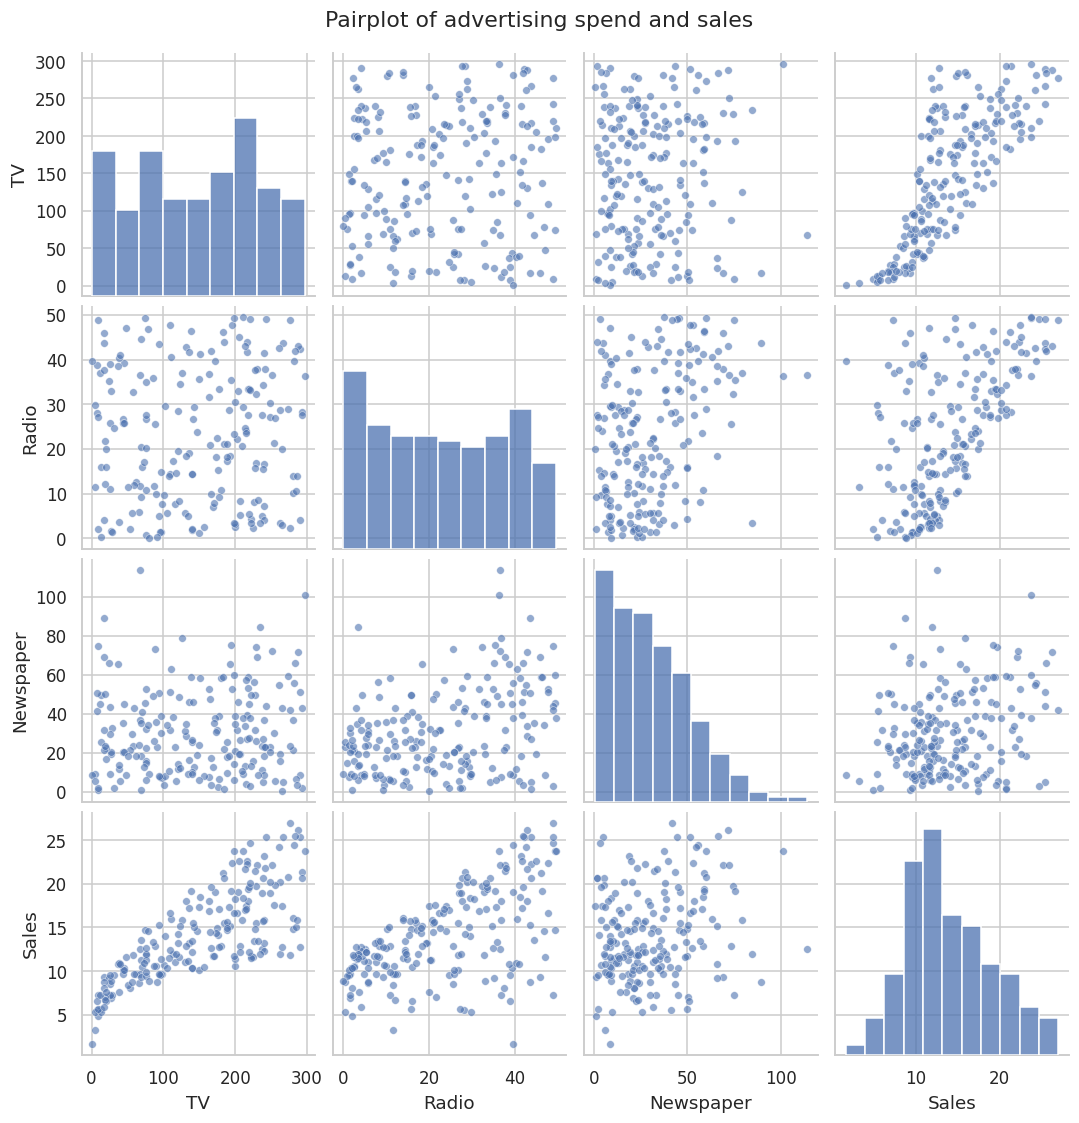

In [4]:
sns.pairplot(df, diag_kind="hist", plot_kws={"alpha": 0.6, "s": 25})
plt.suptitle("Pairplot of advertising spend and sales", y=1.02)
plt.show()

### 3.3 Sales vs each advertising channel

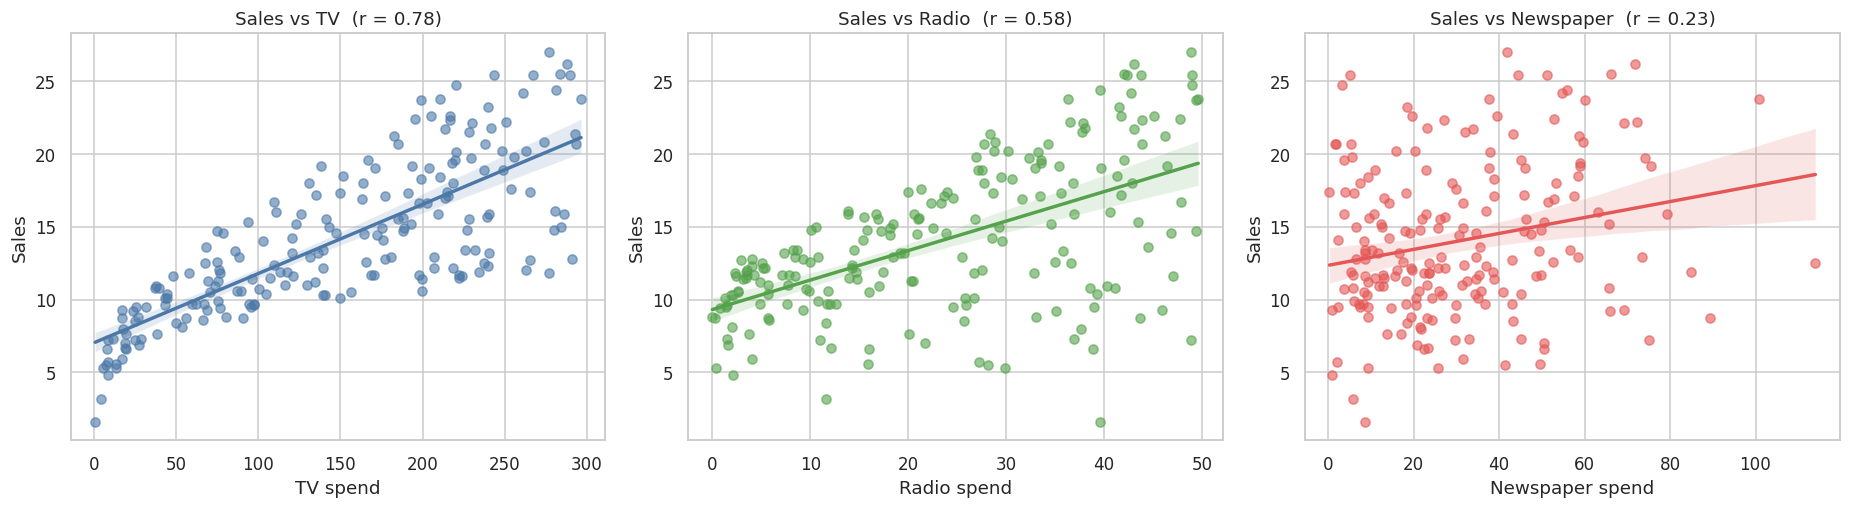

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col, color in zip(axes, ["TV", "Radio", "Newspaper"], ["#4c78a8", "#54a24b", "#e45756"]):
    sns.regplot(data=df, x=col, y="Sales", ax=ax, color=color, scatter_kws={"alpha": 0.6})
    r = df[col].corr(df["Sales"])
    ax.set_title(f"Sales vs {col}  (r = {r:.2f})")
    ax.set_xlabel(f"{col} spend")
plt.tight_layout()
plt.show()

### 3.4 Correlation heatmap

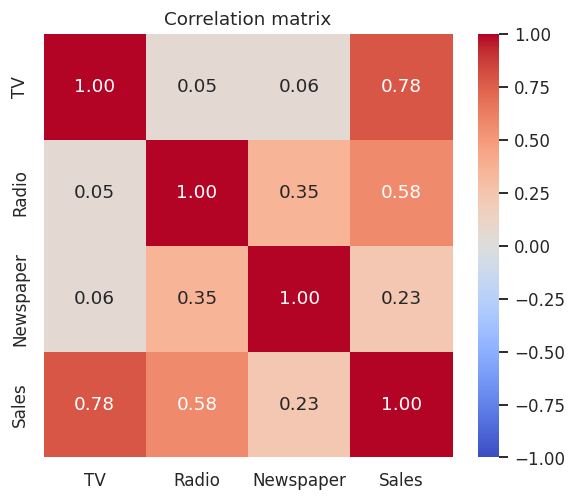

In [6]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation matrix")
plt.show()

**Observations (EDA):**
- **TV has the strongest relationship with sales** (correlation about 0.78) and a clear, almost straight-line trend.
- **Radio is second** (about 0.58); the relationship is positive but the points are more scattered.
- **Newspaper is weak** (about 0.23). Part of that weak link is probably a side effect: newspaper spend is moderately correlated with radio spend (about 0.35), so it can look related to sales simply because it moves together with radio.
- TV and Radio are almost uncorrelated with each other (about 0.05), so each carries separate information.

## 4. Train / test split (80 / 20)

In [7]:
features = ["TV", "Radio", "Newspaper"]
X = df[features]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Training set:", X_train.shape, "| Test set:", X_test.shape)

Training set: (160, 3) | Test set: (40, 3)


## 5. Train the models
1. **Linear Regression** (baseline)
2. **Polynomial Regression** (degree 2: adds squared terms and interactions such as TV x Radio)
3. **Random Forest Regressor**

In [8]:
models = {
    "Linear Regression (baseline)": LinearRegression(),
    "Polynomial Regression (deg 2)": make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
}
for name, model in models.items():
    model.fit(X_train, y_train)
print("Trained", len(models), "models.")

Trained 3 models.


## 6. Evaluate: MAE, RMSE, R-squared
Scores on the 40 held-out test rows. Because 40 rows is small, the 5-fold cross-validated R-squared on all 200 rows is also shown.

                        Model   MAE  RMSE  R2 (test)  R2 (5-fold CV mean)  CV std
Polynomial Regression (deg 2) 0.526 0.643      0.987                0.983   0.008
      Random Forest Regressor 0.613 0.740      0.983                0.980   0.005
 Linear Regression (baseline) 1.461 1.782      0.899                0.883   0.040


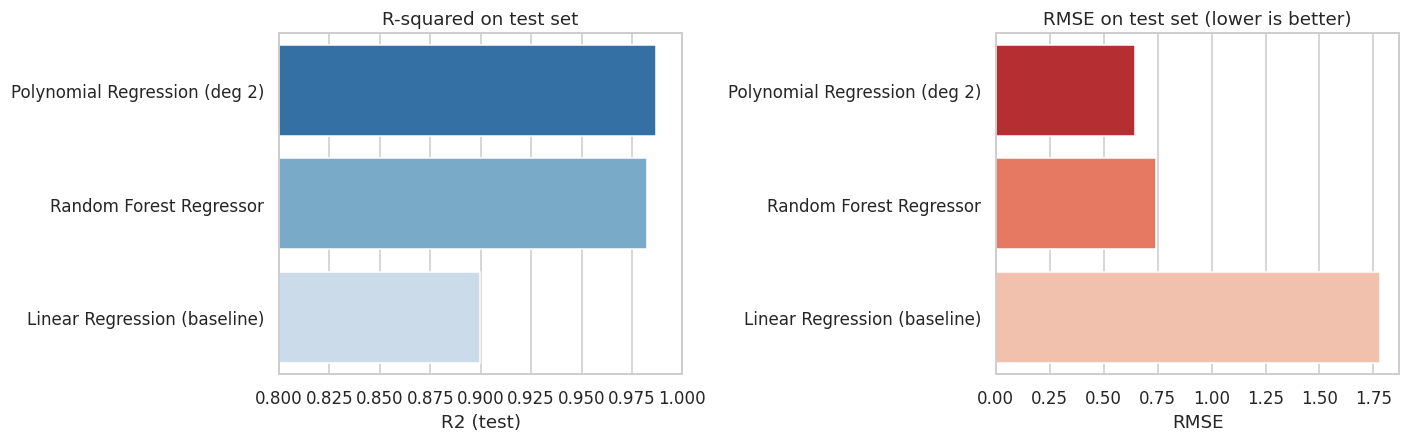

In [9]:
rows = []
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in models.items():
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    cv_r2 = cross_val_score(model, X, y, cv=kf, scoring="r2")
    rows.append([name, mae, rmse, r2, cv_r2.mean(), cv_r2.std()])

results = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE", "R2 (test)", "R2 (5-fold CV mean)", "CV std"])
results = results.sort_values("R2 (5-fold CV mean)", ascending=False).reset_index(drop=True)
print(results.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(data=results, y="Model", x="R2 (test)", ax=axes[0], palette="Blues_r")
axes[0].set_title("R-squared on test set"); axes[0].set_xlim(0.8, 1.0); axes[0].set_ylabel("")
sns.barplot(data=results, y="Model", x="RMSE", ax=axes[1], palette="Reds_r")
axes[1].set_title("RMSE on test set (lower is better)"); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## 7. Best model: actual vs predicted and residuals

Best model: Polynomial Regression (deg 2)
Mean of residuals: 0.017 | Std of residuals: 0.651


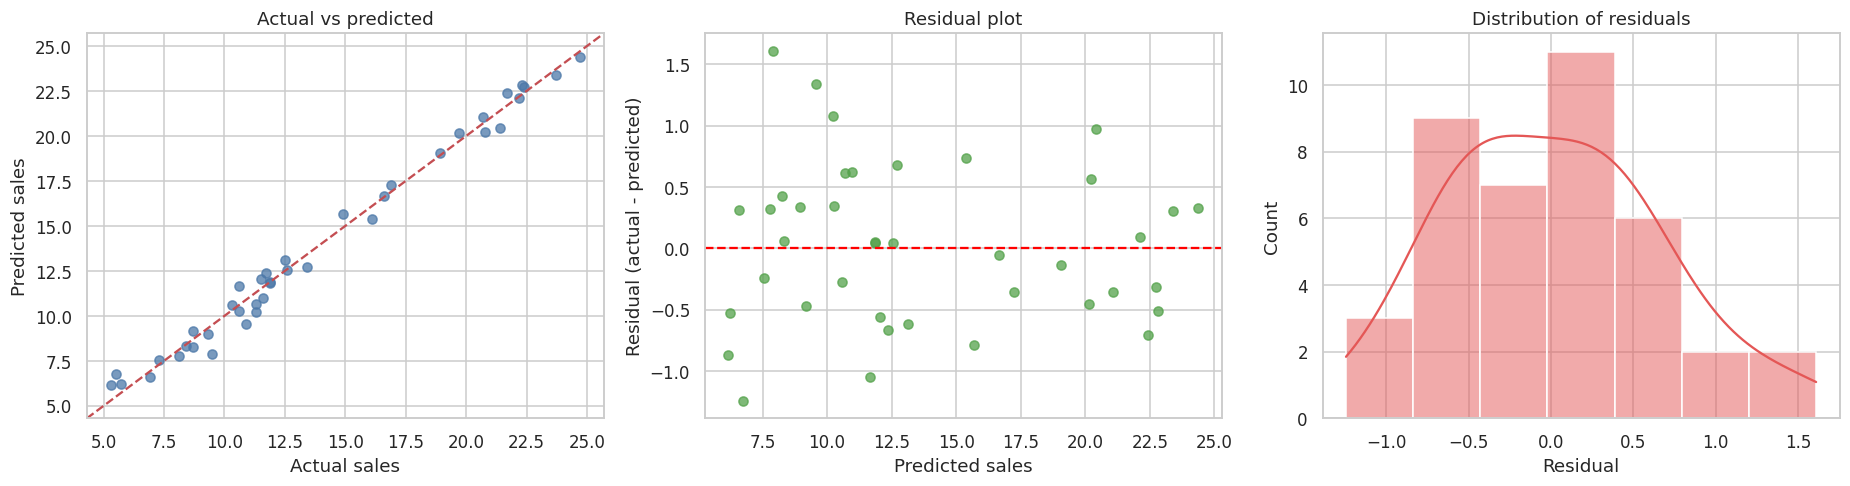

In [10]:
best_name = results.loc[0, "Model"]
best_model = models[best_name]
pred = best_model.predict(X_test)
resid = y_test - pred
print("Best model:", best_name)
print("Mean of residuals: %.3f | Std of residuals: %.3f" % (resid.mean(), resid.std()))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].scatter(y_test, pred, alpha=0.75, color="#4c78a8")
lims = [min(y_test.min(), pred.min()) - 1, max(y_test.max(), pred.max()) + 1]
axes[0].plot(lims, lims, "r--"); axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("Actual sales"); axes[0].set_ylabel("Predicted sales"); axes[0].set_title("Actual vs predicted")

axes[1].scatter(pred, resid, alpha=0.75, color="#54a24b")
axes[1].axhline(0, color="red", ls="--")
axes[1].set_xlabel("Predicted sales"); axes[1].set_ylabel("Residual (actual - predicted)"); axes[1].set_title("Residual plot")

sns.histplot(resid, kde=True, ax=axes[2], color="#e45756")
axes[2].set_xlabel("Residual"); axes[2].set_title("Distribution of residuals")
plt.tight_layout()
plt.show()

**Observation:** The predictions sit close to the red diagonal, and the residuals are scattered randomly around zero (mean about 0.02, std about 0.65 thousand units) with no obvious curve or funnel shape. A few points at low predicted sales are off by about 1.3 to 1.6, but there is no systematic pattern, so the model is not consistently over- or under-predicting in any range. With only 40 test points this is a visual check, not proof.


**Why does the baseline fall behind? Two quick checks** (supporting the conclusion below)

In [11]:
# (a) residuals of the plain linear model grouped by predicted-sales level:
#     a pattern here means the model misses a non-linear effect
lin = LinearRegression().fit(X, y)
lin_res = y - lin.predict(X)
level = pd.qcut(lin.predict(X), 3, labels=["low", "mid", "high"])
print("Linear model: average residual by predicted-sales level")
print(lin_res.groupby(level).mean().round(2))

# (b) does a TV x Radio interaction term help the plain linear model?
X_int = X.copy()
X_int["TV_x_Radio"] = X["TV"] * X["Radio"]
cv_plain = cross_val_score(LinearRegression(), X, y, cv=kf, scoring="r2").mean()
cv_int = cross_val_score(LinearRegression(), X_int, y, cv=kf, scoring="r2").mean()
print("\nCV R2 linear (TV, Radio, Newspaper):        %.3f" % cv_plain)
print("CV R2 linear + TV x Radio interaction term: %.3f" % cv_int)

Linear model: average residual by predicted-sales level
low     0.43
mid    -0.80
high    0.36
Name: Sales, dtype: float64

CV R2 linear (TV, Radio, Newspaper):        0.883
CV R2 linear + TV x Radio interaction term: 0.963


## 8. Which advertising channel has the highest impact on sales?
Three views of the same question:
1. **Linear Regression coefficients** on standardised features (so channels with different budget sizes are comparable)
2. **Raw coefficients** (extra sales per extra unit of spend)
3. **Permutation importance** of the best model (how much the score drops when a channel is shuffled)

  channel  raw coefficient (sales per +1 spend)  standardised coefficient
       TV                                0.0447                     3.764
    Radio                                0.1892                     2.792
Newspaper                                0.0028                     0.056

Permutation importance (Polynomial Regression (deg 2)):
  channel  importance   std
       TV       1.404 0.239
    Radio       0.568 0.100
Newspaper       0.000 0.002


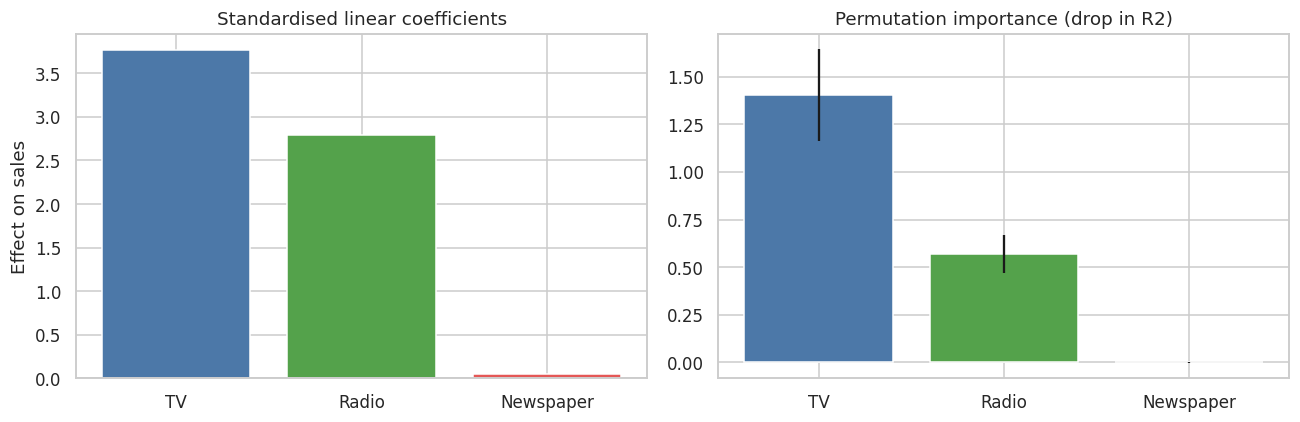

In [12]:
# 1 and 2: linear regression
lin_raw = LinearRegression().fit(X_train, y_train)
scaler = StandardScaler().fit(X_train)
lin_std = LinearRegression().fit(scaler.transform(X_train), y_train)

impact = pd.DataFrame({
    "channel": features,
    "raw coefficient (sales per +1 spend)": lin_raw.coef_.round(4),
    "standardised coefficient": lin_std.coef_.round(3),
})
print(impact.to_string(index=False))

# 3: permutation importance of the best model on the test set
perm = permutation_importance(best_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="r2")
perm_df = pd.DataFrame({"channel": features, "importance": perm.importances_mean, "std": perm.importances_std})
print("\nPermutation importance (" + best_name + "):")
print(perm_df.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(features, lin_std.coef_, color=["#4c78a8", "#54a24b", "#e45756"])
axes[0].set_title("Standardised linear coefficients"); axes[0].set_ylabel("Effect on sales")
axes[1].bar(features, perm.importances_mean, yerr=perm.importances_std, color=["#4c78a8", "#54a24b", "#e45756"])
axes[1].set_title("Permutation importance (drop in R2)")
plt.tight_layout()
plt.show()

## 9. Conclusion

**Model comparison**

| Model | MAE | RMSE | R2 (test) | R2 (5-fold CV) |
|---|---|---|---|---|
| Polynomial Regression (deg 2) | **0.53** | **0.64** | **0.987** | **0.983** |
| Random Forest Regressor | 0.61 | 0.74 | 0.983 | 0.980 |
| Linear Regression (baseline) | 1.46 | 1.78 | 0.899 | 0.883 |

- **Best model: Polynomial Regression (degree 2).** It has the lowest errors and the highest R-squared, both on the test set and in cross-validation. On average its prediction is off by about 0.5 thousand units.
- The Random Forest is almost as good (the gap to the polynomial model is smaller than the fold-to-fold variation, so they are effectively tied). The polynomial model is preferred because it is simpler and easier to explain.
- **The plain Linear Regression baseline is clearly weaker** (R-squared about 0.88-0.90). The check in section 7 shows why: its errors form a U-shape (under-predicts at low and high sales, over-predicts in the middle), and simply adding a **TV x Radio interaction** raises its cross-validated R-squared from 0.88 to 0.96. In other words, TV and Radio spend work better *together* than the sum of their separate effects.

**Which channel has the highest impact?**
- **TV has the highest overall impact on sales.** It has the largest standardised coefficient (3.76 vs 2.79 for Radio) and the largest permutation importance (1.40 vs 0.57).
- **Radio is the most effective per unit of money.** In the linear model, each extra unit of Radio spend is linked with about 0.19 extra sales units, compared with about 0.045 for TV (roughly 4 times as much). TV matters most mainly because the TV budgets are so much bigger.
- **Newspaper has almost no impact** once TV and Radio are in the model (coefficient about 0.003, permutation importance 0.00). Its weak correlation with sales in the EDA came largely from being correlated with Radio spend.

**Business takeaway:** prioritise TV and Radio and use them together; Newspaper spend adds essentially nothing in this data.

**Limitations:** only 200 rows; this is observational data, so the results show association, not proven cause and effect; and a model fitted on these budget ranges should not be trusted far outside them (TV 0.7-296, Radio 0-50, Newspaper 0.3-114).


## 10. Predicting sales for a new budget (demo)

In [13]:
new_budget = pd.DataFrame([[150.0, 30.0, 20.0]], columns=features)   # TV, Radio, Newspaper
print("Best model:", best_name)
print("Budget (TV, Radio, Newspaper):", new_budget.values.tolist()[0])
print("Predicted sales: %.2f thousand units" % best_model.predict(new_budget)[0])

Best model: Polynomial Regression (deg 2)
Budget (TV, Radio, Newspaper): [150.0, 30.0, 20.0]
Predicted sales: 16.11 thousand units
